In [1]:
from google.colab import drive
drive.mount('/content/gdrive')
%cd /content/gdrive/MyDrive/estruturas

Mounted at /content/gdrive
/content/gdrive/MyDrive/estruturas


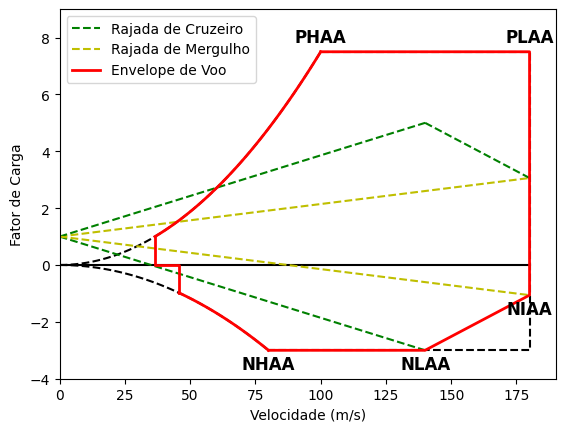

Distribuição de Sustentação e Arrasto ao longo da Semi-Envergadura


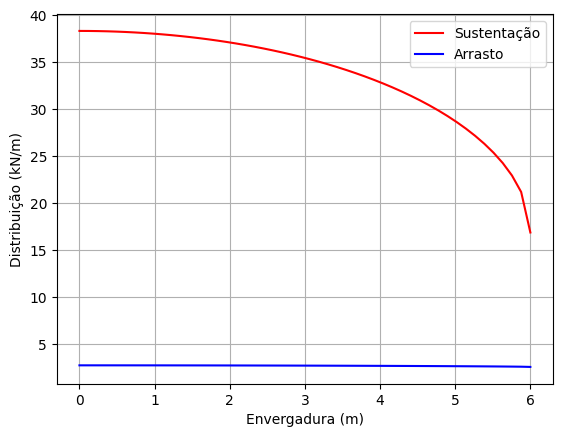

Decomposição da Distribuição dos Esforços ao longo da Semi-Envergadura


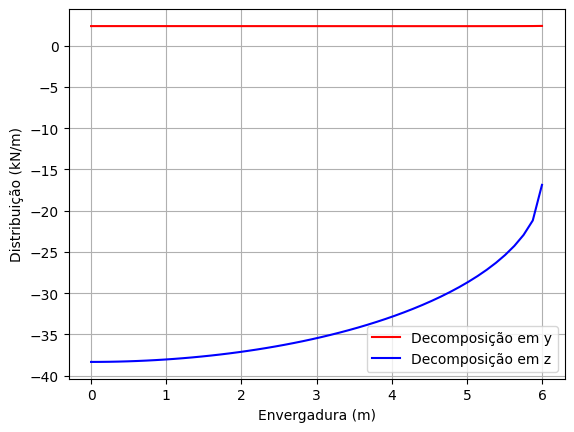

Momento de Arfagem ao longo da Semi-Envergadura


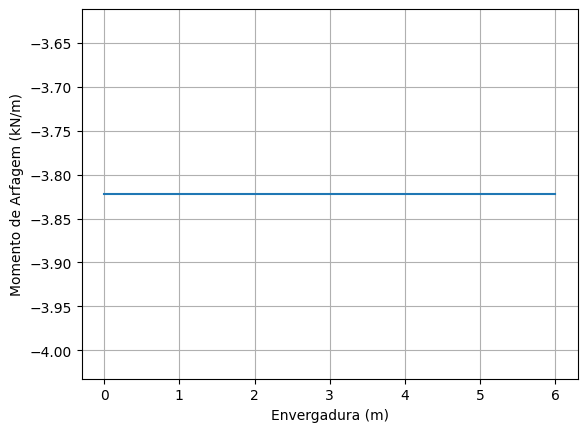

Momento Torsor ao longo da Semi-Envergadura


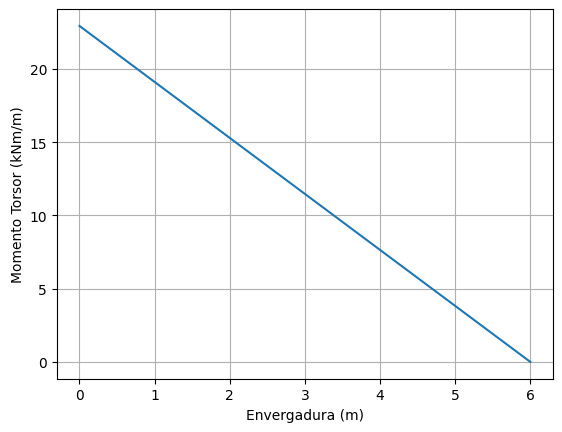

Esforço Cortante ao longo da Semi-Envergadura


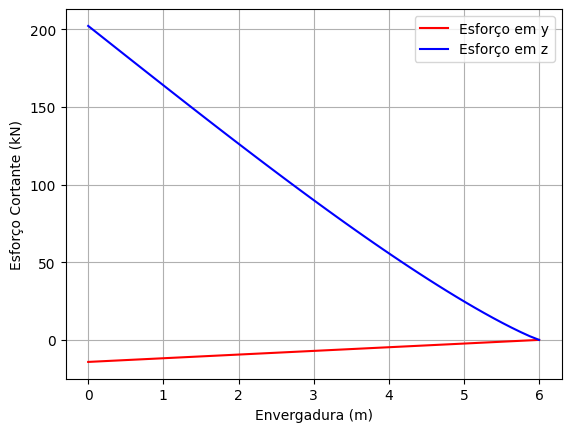

Momento Fletor ao longo da Semi-Envergadura


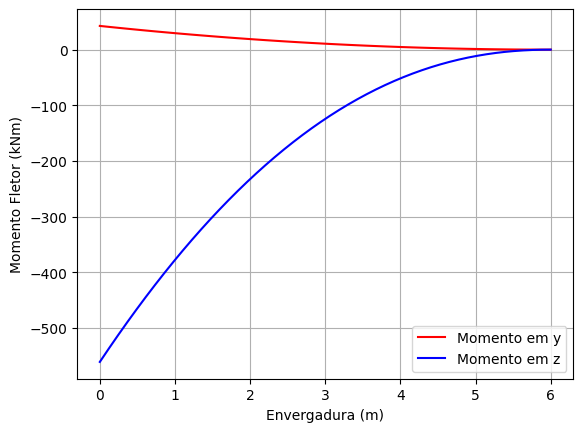

Área ponderada: 0.009229 m²

Posição y centroide ponderado: 1.0 m
Posição z centroide ponderado: 0.2508 m
Momento de inércia Iyy*: 0.0004584 kgm²
Momento de inércia Izz*: 0.003848 kgm²
Produto de inércia Iyz*: 0 kgm²
Ângulo do Eixo Neutro: 32.52 °


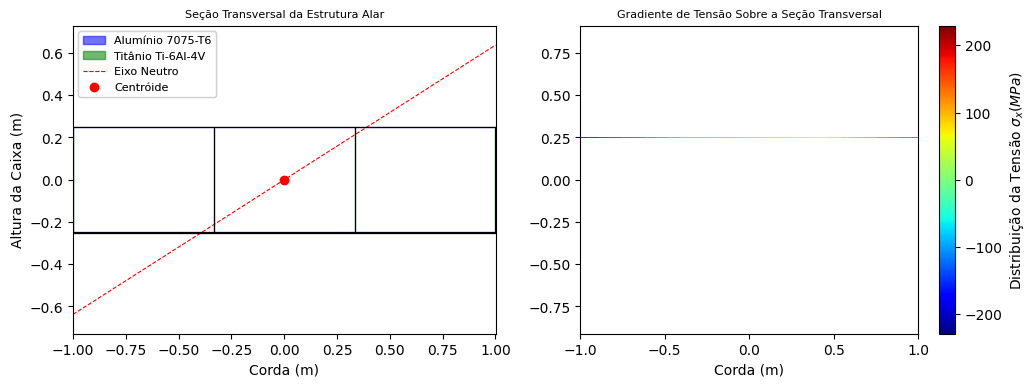

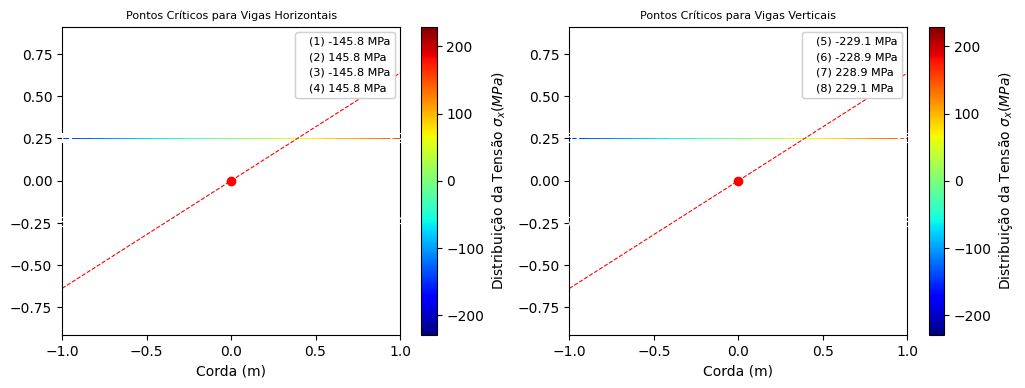

Tensão máxima positiva: 229.1 MPa
Tensão máxima negativa: -229.1 MPa
Deflexão no eixo y e z em função da semi envergadura


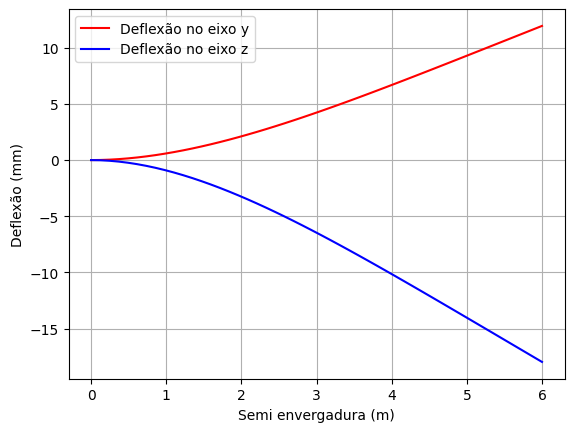

Deflexão máxima em y: 11.94 mm
Deflexão máxima em z: 17.97 mm
Taxa de variação do ângulo de torção ao longo da semi-envergadura


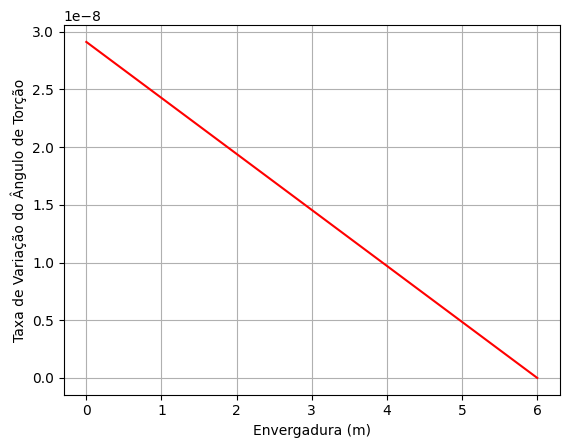

Variação do ângulo de torção ao longo da semi-envergadura


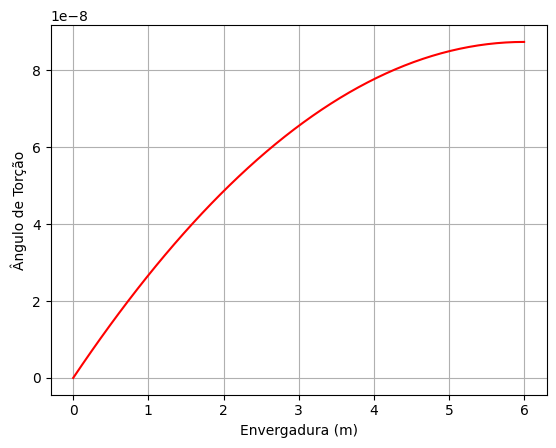


Fluxo de cisalhamento na primeira seção: 0.4739
Fluxo de cisalhamento na segunda seção: 0.5454
Fluxo de cisalhamento na terceira seção: 0.4739

Gradiente de Tensão Cisalhante


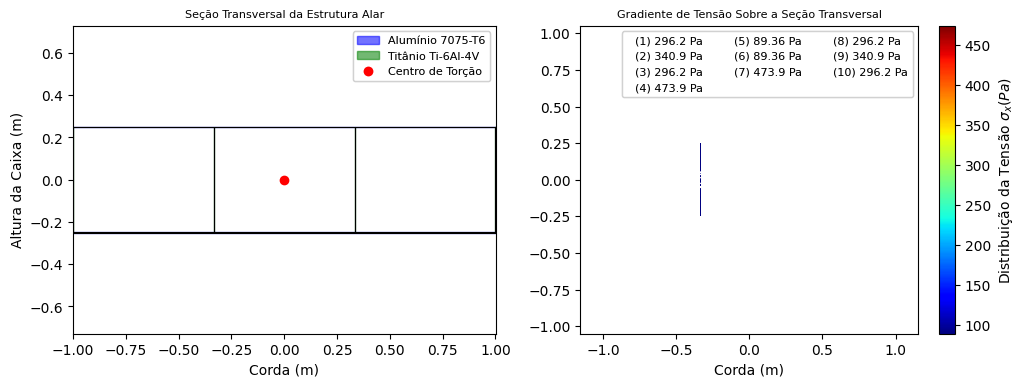

Tensão cisalhante máxima positiva: 473.9 Pa
Tensão cisalhante máxima negativa: 89.36 Pa


In [5]:
#@title codigo
class parametros_analise:

    def __init__(self,condicao,dimensoes,mtow):

        self.dim_enverg = dimensoes[0]
        self.dim_corda = dimensoes[1]
        self.esp_1 = dimensoes[2]
        self.esp_2 = dimensoes[3]
        self.esp_3 = dimensoes[4]
        self.dim_h = dimensoes[5]
        self.mtow = mtow

        #Escolha da condição do V-n
        if condicao == 1:
            self.fator_carga = 7.5
            self.alpha = 22
            self.velocidade = 100
        elif condicao == 2:
            self.fator_carga = 7.5
            self.alpha = 8
            self.velocidade = 180
        elif condicao == 3:
            self.fator_carga = -3
            self.alpha = -19
            self.velocidade = 80
        elif condicao == 4:
            self.fator_carga = -3
            self.alpha = -8.7
            self.velocidade = 140
        elif condicao == 5:
            self.fator_carga = -1.06
            self.alpha = -3.8
            self.velocidade = 180

    def material_1(self):
        self.modulo_elasticidade = 70e9
        self.coef_poisson = 0.3
        self.tensao_escoamento = 400e6
        self.modulo_cisalhamento = 26e9
        return self.modulo_elasticidade, self.coef_poisson, self.tensao_escoamento, self.modulo_cisalhamento

    def material_2(self):
        self.modulo_elasticidade = 110e9
        self.coef_poisson = 0.3
        self.tensao_escoamento = 1100e6
        self.modulo_cisalhamento = 45e9
        return self.modulo_elasticidade, self.coef_poisson, self.tensao_escoamento, self.modulo_cisalhamento

import PARAMETROS
import RESULTADOS
import VN
from AERODINAMICA import calculos_aerodinamica
from google.colab import output
from PROPRIEDADES_AREA import A_pond, centroide_pond, I_pond

densidade = 1.225
visc_din = 1.7894e-5
gravidade = 9.80665
cd0 = 0.017
k = 0.021

condicao = int(input(f'Selecione qual das condições você deseja calcular: \n\n{" ":>4}(1) PHAA \n{" ":>4}(2) PLAA\n{" ":>4}(3) NHAA\n{" ":>4}(4) NIAA\n{" ":>4}(5) NLAA\n{" ":>4}\n'))
output.clear()
dim_enverg = float(input('Digite a dimensão da envergadura b [m]:  \n'))
output.clear()
dim_corda = float(input('Digite a dimensão da corda c [m]:   \n'))
output.clear()
dim_h = float(input('Digite a dimensão da altura da caixa h [m]:   \n'))
output.clear()
esp_1 = float(input('Digite a espessura t1 [m]:  \n'))
output.clear()
esp_2 = float(input('Digite a espessura t2 [m]:  \n'))
output.clear()
esp_3 = float(input('Digite a espessura t3 [m]:  \n'))
output.clear()
mtow = float(input('Digite o peso máximo de decolagem [Kg]:  \n'))
output.clear()

dimensoes = [dim_enverg, dim_corda, esp_1, esp_2, esp_3, dim_h]
inputs = parametros_analise(condicao,dimensoes,mtow)

PARAMETROS.GRAVIDADE = gravidade
PARAMETROS.VISC_DIN = visc_din
PARAMETROS.DENSIDADE = densidade
PARAMETROS.CD0 = cd0
PARAMETROS.K = k
PARAMETROS.FATOR_CARGA = inputs.fator_carga
PARAMETROS.ALPHA = inputs.alpha
PARAMETROS.VELOCIDADE = inputs.velocidade
PARAMETROS.MODULO_ELASTICIDADE_1, PARAMETROS.COEF_POISSON_1, PARAMETROS.TENSAO_ESCOAMENTO_1, PARAMETROS.MODULO_CISALHAMENTO_1 = inputs.material_1()
PARAMETROS.MODULO_ELASTICIDADE_2, PARAMETROS.COEF_POISSON_2, PARAMETROS.TENSAO_ESCOAMENTO_2, PARAMETROS.MODULO_CISALHAMENTO_2 = inputs.material_2()
PARAMETROS.DIM_ENVERG = inputs.dim_enverg
PARAMETROS.DIM_CORDA = inputs.dim_corda
PARAMETROS.DIM_H = inputs.dim_h
PARAMETROS.ESP_1 = inputs.esp_1
PARAMETROS.ESP_2 = inputs.esp_2
PARAMETROS.ESP_3 = inputs.esp_3
PARAMETROS.MTOW = inputs.mtow

#Cálculos aerodinâmicos
L, D, M, _, _, _ = calculos_aerodinamica()
VN.vn()

#Plots das cargas externas
import PLOTS
PLOTS.sust_arrast();
PLOTS.cargas()
PLOTS.momento_arfagem_torsor()
PLOTS.momento_torsor()

#Plots diagramas dos esforços internos
PLOTS.esforco_cortante();
My, Mz = PLOTS.momento_fletor()
RESULTADOS.MY, RESULTADOS.MZ = My, Mz

#Cálculo área ponderada
area_ponderada = A_pond()
print(f"Área ponderada: {area_ponderada:.4} m²\n")

#Cálculo do centroide ponderado
y0_pond, z0_pond = centroide_pond()
RESULTADOS.Y0_POND, RESULTADOS.Z0_POND = y0_pond, z0_pond
print(f'Posição y centroide ponderado: {y0_pond:.4} m\nPosição z centroide ponderado: {z0_pond:.4} m')

#Cálculo momentos e produto de inércia ponderados
Iyy_pond, Izz_pond, Iyz_pond = I_pond()
RESULTADOS.IYY_POND, RESULTADOS.IZZ_POND, RESULTADOS.IYZ_POND = Iyy_pond, Izz_pond, Iyz_pond
print(f'Momento de inércia Iyy*: {Iyy_pond:.4} kgm²\nMomento de inércia Izz*: {Izz_pond:.4} kgm²\nProduto de inércia Iyz*: {Iyz_pond} kgm²')

#Identificação do eixo neutro
from EIXO_NEUTRO import angulo_eixo_neutro
ang_neut = angulo_eixo_neutro()
RESULTADOS.ANG_NEUT = ang_neut
print(f'Ângulo do Eixo Neutro: {(ang_neut+90):.4} °')

#Distribuição das tensões em pontos críticos
import TENSAO
v_max, v_min = TENSAO.dist_tensao()
print(f'Tensão máxima positiva: {(v_max/1e6):.4} MPa\nTensão máxima negativa: {(v_min/1e6):.4} MPa')

#Cálculo das deflexões
import DEFLEXAO
d_maxy, d_maxz = DEFLEXAO.calc_deflexao()
print(f'Deflexão máxima em y: {(d_maxy*1e3):.4} mm\nDeflexão máxima em z: {(d_maxz*1e3):.4} mm')

#Plot da distribuição do fluxo de cisalhamento e da variação do ângulo de torção
import TORCAO
q = TORCAO.dist_ang()
print(f'\nFluxo de cisalhamento na primeira seção: {(q[0]):.4}\nFluxo de cisalhamento na segunda seção: {(q[1]):.4}\nFluxo de cisalhamento na terceira seção: {(q[2]):.4}\n')

import CISALHAMENTO
v_max_cis, v_min_cis = CISALHAMENTO.dist_tensao_cis()
print(f'Tensão cisalhante máxima positiva: {(v_max_cis):.4} Pa\nTensão cisalhante máxima negativa: {(v_min_cis):.4} Pa')

REFORÇADORES NOS PAINEIS HORIZONTAIS

Tensão máxima compressão: 229.1 MPa
Tensão crítica simulada: 572.8 MPa
Tensão crítica teórica sem reforçadores: 29.93 MPa
Número reforçadores = 4.375
Número inteiro de reforçadores = 4
Distância inicial entre reforçadores = 152.8 mm
Distância final entre reforçadores = 139.7 mm
Tensão crítica teórica com reforçadores: 685.1 MPa
Largura base reforçador = 27.94 mm
Largura fixação reforçador = 13.97 mm
Espessura reforçador = 0.5333 mm
Altura do reforçador = 25.0 mm


REFORÇADORES NOS PAINEIS VERTICAIS

Tensão máxima compressão: 229.1 MPa
Tensão crítica teórica: 92.22 MPa
Tensão crítica simulada: 572.8 MPa
Número reforçadores = 2.492
Número inteiro de reforçadores = 2
Distância inicial entre reforçadores = 201.9 mm
Distância final entre reforçadores = 162.0 mm
Tensão crítica teórica: 889.4 MPa


NERVURAS

Momento de inércia do reforçador = 4.546e-08
Raio de giração = 0.008067
Tensão crítica sem nervuras = 1.249 MPa
Número nervuras = 21.42
Número inteir

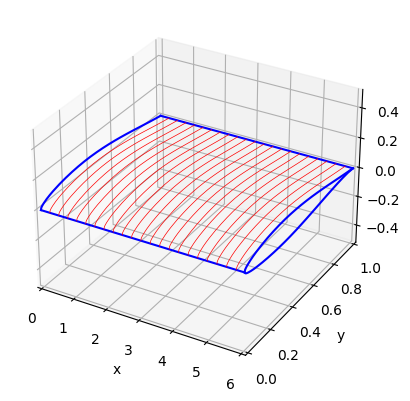

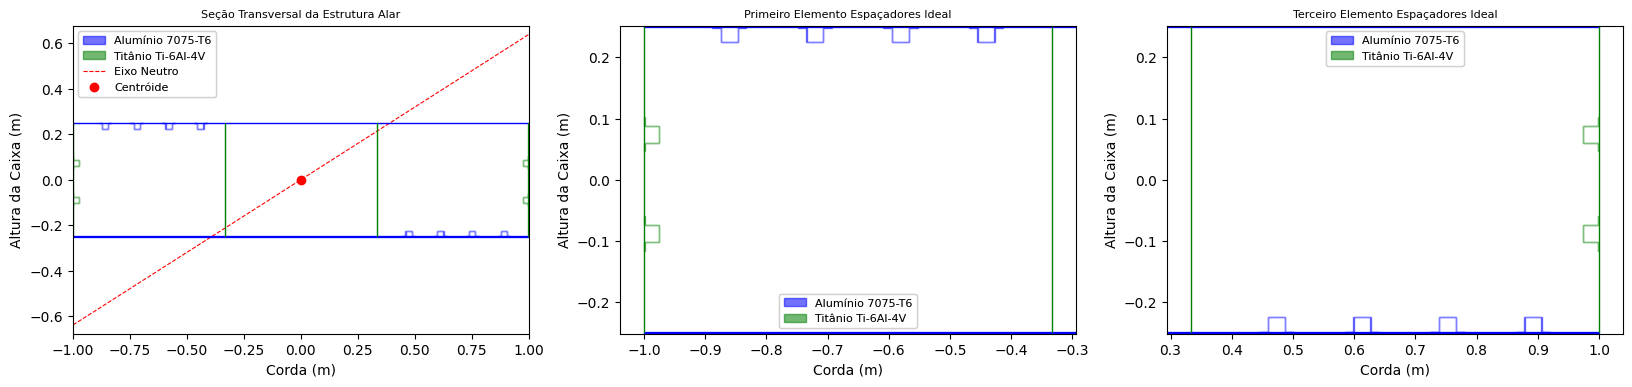

In [4]:
#@title codigo
import numpy as np
import math
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def flambagem(condicao,v_max):
  E1, E2 = PARAMETROS.MODULO_ELASTICIDADE_1, PARAMETROS.MODULO_ELASTICIDADE_2
  t1, t2, t3, c, h, b = PARAMETROS.ESP_1, PARAMETROS.ESP_2, PARAMETROS.ESP_3, PARAMETROS.DIM_CORDA, PARAMETROS.DIM_H, PARAMETROS.DIM_ENVERG
  x, y = RESULTADOS.Y0_POND, RESULTADOS.Z0_POND
  alpha = RESULTADOS.ANG_NEUT
  angulo_rad = np.radians(alpha+90)

  b1_0 = 0-x; b1_1 = t2+c-x; h1_0 = h-y; h1_1 = h+t1-y
  b2_0 = 0-x; b2_1 = t2+c-x; h2_0 = 0-y; h2_1 = t1-y
  b3_0 = 0-x; b3_1 = t2-x; h3_0 = t1-y; h3_1 = h-y
  b4_0 = c-x; b4_1 = t2+c-x; h4_0 = t1-y; h4_1 = h-y
  b5_0 = c/3-x; b5_1 = c/3+t3 - x; h5_0 = t1-y; h5_1 = h-y
  b6_0 = 2*c/3-x; b6_1 = 2*c/3+t3 - x; h6_0 = t1-y; h6_1 = h-y

  x10 = [b1_0, b1_1, b1_1, b1_0, b1_0]
  y10 = [h1_0, h1_0, h1_1, h1_1, h1_0]
  x20 = [b2_0, b2_1, b2_1, b2_0, b2_0]
  y20 = [h2_0, h2_0, h2_1, h2_1, h2_0]
  x30 = [b3_0, b3_1, b3_1, b3_0, b3_0]
  y30 = [h3_0, h3_0, h3_1, h3_1, h3_0]
  x40 = [b4_0, b4_1, b4_1, b4_0, b4_0]
  y40 = [h4_0, h4_0, h4_1, h4_1, h4_0]
  x50 = [b5_0, b5_1, b5_1, b5_0, b5_0]
  y50 = [h5_0, h5_0, h5_1, h5_1, h5_0]
  x60 = [b6_0, b6_1, b6_1, b6_0, b6_0]
  y60 = [h6_0, h6_0, h6_1, h6_1, h6_0]


  dim_corda = c
  FS = 2.5
  tensao_crit_sim = FS*v_max
  t = t1
  v = 0.3
  E = 70e9
  m = 1
  a = b/2
  b1 = np.abs(-c/2-t2-(-c/6+t3))
  k = (m*b1/a+a/(m*b1))**2

  tensao_crit_teo = ((k*(np.pi**2)*E)/(12*(1-v**2)))*(t/b1)**2
  dist_ref = np.sqrt((k*(np.pi**2)*E)/(12*(1-v**2)))*(t/np.sqrt(tensao_crit_sim))
  xnum = b1/(dist_ref)
  valor_inteiro = math.floor(xnum)
  diferenca =  (b1-valor_inteiro*dist_ref)/xnum
  distancia = dist_ref-diferenca
  tensao_crit_teo_otm = ((k*(np.pi**2)*E)/(12*(1-v**2)))*(t/distancia)**2

  bref = 0.2*distancia
  eref = t/3
  breffix = bref/2
  href = 0.05*h

  area_ref = bref*href
  I_ref = (bref**3*href)/12
  raio_gir = np.sqrt(I_ref/area_ref)
  sigma_crit_s_nerv = ((np.pi**2)*E)/(((b/2)/raio_gir)**2)
  le = np.sqrt((np.pi**2*E)/tensao_crit_sim)*raio_gir
  xnum_nerv = (b/2)/(le)
  valor_inteiro_nerv = math.floor(xnum_nerv)
  diferenca_nerv =  (b/2-valor_inteiro_nerv*le)/xnum_nerv
  distancia_nerv = le-diferenca_nerv

  tnerv = t/3

  tensao_crit_teo_otm_nerv = (np.pi**2)*E*(raio_gir/distancia_nerv)**2
  b1_lat = np.abs(-h/2-t1-(h/2+t1))
  k_lat = (m*b1_lat/a+a/(m*b1_lat))**2
  tensao_crit_teo_lat = ((k_lat*(np.pi**2)*E)/(12*(1-v**2)))*(t/b1_lat)**2
  dist_ref_lat = np.sqrt((k_lat*(np.pi**2)*E)/(12*(1-v**2)))*(t/np.sqrt(tensao_crit_sim))
  xnum_lat = b1_lat/(dist_ref_lat)
  valor_inteiro_lat = math.floor(xnum_lat)
  diferenca_lat = (b1_lat-valor_inteiro_lat*dist_ref_lat)/xnum_lat
  distancia_lat = dist_ref_lat-diferenca_lat
  tensao_crit_teo_otm_lat = ((k_lat*(np.pi**2)*E)/(12*(1-v**2)))*(t/distancia_lat)**2


  print(f'REFORÇADORES NOS PAINEIS HORIZONTAIS'
        f'\n\nTensão máxima compressão: {(v_max/1e6):.4} MPa'
        f'\nTensão crítica simulada: {(tensao_crit_sim/1e6):.4} MPa'
        f'\nTensão crítica teórica sem reforçadores: {(tensao_crit_teo/1e6):.4} MPa'
        f'\nNúmero reforçadores = {xnum:.4}'
        f'\nNúmero inteiro de reforçadores = {round(xnum)}'
        f'\nDistância inicial entre reforçadores = {(dist_ref*1e3):.4} mm'
        f'\nDistância final entre reforçadores = {(distancia*1e3):.4} mm'
        f'\nTensão crítica teórica com reforçadores: {(tensao_crit_teo_otm/1e6):.4} MPa'
        f'\nLargura base reforçador = {(bref*1e3):.4} mm'
        f'\nLargura fixação reforçador = {(breffix*1e3):.4} mm'
        f'\nEspessura reforçador = {(eref*1e3):.4} mm'
        f'\nAltura do reforçador = {(href*1e3):.4} mm\n\n\n'
        f'REFORÇADORES NOS PAINEIS VERTICAIS'
        f'\n\nTensão máxima compressão: {(v_max/1e6):.4} MPa'
        f'\nTensão crítica teórica: {(tensao_crit_teo_lat/1e6):.4} MPa'
        f'\nTensão crítica simulada: {(tensao_crit_sim/1e6):.4} MPa'
        f'\nNúmero reforçadores = {xnum_lat:.4}'
        f'\nNúmero inteiro de reforçadores = {round(xnum_lat)}'
        f'\nDistância inicial entre reforçadores = {(dist_ref_lat*1e3):.4} mm'
        f'\nDistância final entre reforçadores = {(distancia_lat*1e3):.4} mm'
        f'\nTensão crítica teórica: {(tensao_crit_teo_otm_lat/1e6):.4} MPa\n\n\n'
        f'NERVURAS'
        f'\n\nMomento de inércia do reforçador = {(I_ref):.4}'
        f'\nRaio de giração = {(raio_gir):.4}'
        f'\nTensão crítica sem nervuras = {(sigma_crit_s_nerv/1e6):.4} MPa'
        f'\nNúmero nervuras = {xnum_nerv:.4}'
        f'\nNúmero inteiro de nervuras = {valor_inteiro_nerv}'
        f'\nDistância inicial entre nervuras = {(le*1e3):.4} mm'
        f'\nDistância final entre nervuras = {(distancia_nerv*1e3):.4} mm'
        f'\nEspessura nervura = {(tnerv)*1e3:.4}'
        f'\nTensão crítica teórica com nervuras: {(tensao_crit_teo_otm_nerv/1e6):.4} MPa')

  if condicao == 5:
    #POSIÇÕES REFORÇADORES LADO SUPERIOR DIREITO
    pos_ref_x5 = [2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+0]
    pos_ref_x6 = [2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref, 2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+0]
    pos_ref_x7 = [2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref, 2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+0]
    pos_ref_x8 = [2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+0]
    pos_ref_y2 = [h-y+0,h-y+0,h-y+-href+eref,h-y+-href+eref,h-y+0,h-y+0,h-y+-eref,h-y+-eref,h-y+-href,h-y+-href,h-y+-eref,h-y+-eref,h-y+0]

    #POSIÇÕES REFORÇADORES LADO INFERIOR ESQUERDO
    pos_ref_x13 = [-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+0]
    pos_ref_x14 = [-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+0]
    pos_ref_x15 = [-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+0]
    pos_ref_x16 = [-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+0]
    pos_ref_y3 = [-y+0+t1,-y+0+t1,-y+href-eref+t1,-y+href-eref+t1,-y+0+t1,-y+0+t1,-y+eref+t1,-y+eref+t1,-y+href+t1,-y+href+t1,-y+eref+t1,-y+eref+t1,-y+0+t1]

    #POSIÇÕES REFORÇADORES LATERAL DIREITO
    pos_ref_x2_lat = [c-t2-x+0,c-t2-x-eref,c-t2-x-eref,c-t2-x-href,c-t2-x-href,c-t2-x-eref,c-t2-x-eref,c-t2-x+0,c-t2-x+0,c-t2-x-href+eref,c-t2-x-href+eref,c-t2-x+0,c-t2-x+0]
    pos_ref_y3_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
    pos_ref_y4_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

    #POSIÇÕES REFORÇADORES LATERAL ESQUERDO
    pos_ref_x1_lat = [t2-x+0,t2-x+eref,t2-x+eref,t2-x+href,t2-x+href,t2-x+eref,t2-x+eref,t2-x+0,t2-x+0,t2-x+href-eref,t2-x+href-eref,t2-x+0,t2-x+0]
    pos_ref_y1_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
    pos_ref_y2_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

  if condicao == 1 or condicao == 3:
    #POSIÇÕES REFORÇADORES LADO SUPERIOR ESQUERDO
    pos_ref_x1 = [-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+0]
    pos_ref_x2 = [-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+0]
    pos_ref_x3 = [-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+0]
    pos_ref_x4 = [-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+0]
    pos_ref_y1 = [h-y+0,h-y+0,h-y+-href+eref,h-y+-href+eref,h-y+0,h-y+0,h-y+-eref,h-y+-eref,h-y+-href,h-y+-href,h-y+-eref,h-y+-eref,h-y+0]

    #POSIÇÕES REFORÇADORES LADO INFERIOR DIREITO
    pos_ref_x5 = [2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+0]
    pos_ref_x6 = [2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+0]
    pos_ref_x7 = [2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+0]
    pos_ref_x8 = [2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+0]
    pos_ref_y2 = [-y+0+t1,-y+0+t1,-y+href-eref+t1,-y+href-eref+t1,-y+0+t1,-y+0+t1,-y+eref+t1,-y+eref+t1,-y+href+t1,-y+href+t1,-y+eref+t1,-y+eref+t1,-y+0+t1]

    #POSIÇÕES REFORÇADORES LATERAL ESQUERDO
    pos_ref_x1_lat = [t2-x+0,t2-x+eref,t2-x+eref,t2-x+href,t2-x+href,t2-x+eref,t2-x+eref,t2-x+0,t2-x+0,t2-x+href-eref,t2-x+href-eref,t2-x+0,t2-x+0]
    pos_ref_y1_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
    pos_ref_y2_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

    if condicao == 1:
      #POSIÇÕES REFORÇADORES LATERAL DIREITO
      pos_ref_x2_lat = [c-t2-x+0,c-t2-x-eref,c-t2-x-eref,c-t2-x-href,c-t2-x-href,c-t2-x-eref,c-t2-x-eref,c-t2-x+0,c-t2-x+0,c-t2-x-href+eref,c-t2-x-href+eref,c-t2-x+0,c-t2-x+0]
      pos_ref_y3_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
      pos_ref_y4_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

    if condicao == 3:
      #POSIÇÕES REFORÇADORES LATERAL DIREITO
      pos_ref_x2_lat = [c-t2-x+0,c-t2-x-eref,c-t2-x-eref,c-t2-x-href,c-t2-x-href,c-t2-x-eref,c-t2-x-eref,c-t2-x+0,c-t2-x+0,c-t2-x-href+eref,c-t2-x-href+eref,c-t2-x+0,c-t2-x+0]
      pos_ref_y3_lat = [-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+0]
      pos_ref_y4_lat = [-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+0]

  if condicao == 2 or condicao == 4:
    #POSIÇÕES REFORÇADORES LADO SUPERIOR ESQUERDO
    pos_ref_x1 = [-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+0]
    pos_ref_x2 = [-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+0]
    pos_ref_x3 = [-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+0]
    pos_ref_x4 = [-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+0]
    pos_ref_y1 = [h-y+0,h-y+0,h-y+-href+eref,h-y+-href+eref,h-y+0,h-y+0,h-y+-eref,h-y+-eref,h-y+-href,h-y+-href,h-y+-eref,h-y+-eref,h-y+0]

    #POSIÇÕES REFORÇADORES LADO SUPERIOR DIREITO
    pos_ref_x5 = [2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+0]
    pos_ref_x6 = [2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref, 2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+0]
    pos_ref_x7 = [2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref, 2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+0]
    pos_ref_x8 = [2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref, 2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref, 2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+0]
    pos_ref_y2 = [h-y+0,h-y+0,h-y+-href+eref,h-y+-href+eref,h-y+0,h-y+0,h-y+-eref,h-y+-eref,h-y+-href,h-y+-href,h-y+-eref,h-y+-eref,h-y+0]

    #POSIÇÕES REFORÇADORES LADO INFERIOR DIREITO
    pos_ref_x9 = [2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+breffix,2*dim_corda/3-bref+t2/2+distancia-x+0,2*dim_corda/3-bref+t2/2+distancia-x+0]
    pos_ref_x10 = [2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+breffix,2*dim_corda/3-bref+t2/2+2*distancia-x+0,2*dim_corda/3-bref+t2/2+2*distancia-x+0]
    pos_ref_x11 = [2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+breffix,2*dim_corda/3-bref+t2/2+3*distancia-x+0,2*dim_corda/3-bref+t2/2+3*distancia-x+0]
    pos_ref_x12 = [2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref-eref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+2*breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix+bref,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+breffix,2*dim_corda/3-bref+t2/2+4*distancia-x+0,2*dim_corda/3-bref+t2/2+4*distancia-x+0]
    pos_ref_y3 = [-y+0+t1,-y+0+t1,-y+href-eref+t1,-y+href-eref+t1,-y+0+t1,-y+0+t1,-y+eref+t1,-y+eref+t1,-y+href+t1,-y+href+t1,-y+eref+t1,-y+eref+t1,-y+0+t1]

    #POSIÇÕES REFORÇADORES LADO INFERIOR ESQUERDO
    pos_ref_x13 = [-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+breffix+bref-eref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+2*breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix+bref,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+breffix,-bref+t2/2+distancia-x+0,-bref+t2/2+distancia-x+0]
    pos_ref_x14 = [-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+breffix+bref-eref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+2*breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix+bref,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+breffix,-bref+t2/2+2*distancia-x+0,-bref+t2/2+2*distancia-x+0]
    pos_ref_x15 = [-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+breffix+bref-eref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+2*breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix+bref,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+breffix,-bref+t2/2+3*distancia-x+0,-bref+t2/2+3*distancia-x+0]
    pos_ref_x16 = [-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+breffix+bref-eref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+2*breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix+bref,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+breffix,-bref+t2/2+4*distancia-x+0,-bref+t2/2+4*distancia-x+0]
    pos_ref_y4 = [-y+0+t1,-y+0+t1,-y+href-eref+t1,-y+href-eref+t1,-y+0+t1,-y+0+t1,-y+eref+t1,-y+eref+t1,-y+href+t1,-y+href+t1,-y+eref+t1,-y+eref+t1,-y+0+t1]

    if condicao == 2:
      #POSIÇÕES REFORÇADORES LATERAL DIREITO
      pos_ref_x2_lat = [c-t2-x+0,c-t2-x-eref,c-t2-x-eref,c-t2-x-href,c-t2-x-href,c-t2-x-eref,c-t2-x-eref,c-t2-x+0,c-t2-x+0,c-t2-x-href+eref,c-t2-x-href+eref,c-t2-x+0,c-t2-x+0]
      pos_ref_y3_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
      pos_ref_y4_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

      #POSIÇÕES REFORÇADORES LATERAL ESQUERDO
      pos_ref_x1_lat = [t2-x+0,t2-x+eref,t2-x+eref,t2-x+href,t2-x+href,t2-x+eref,t2-x+eref,t2-x+0,t2-x+0,t2-x+href-eref,t2-x+href-eref,t2-x+0,t2-x+0]
      pos_ref_y1_lat = [t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-y-bref+0,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+2*breffix+bref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+bref-eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+breffix+eref,t1/2+distancia_lat-bref-y+0]
      pos_ref_y2_lat = [t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-y-bref+0,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+2*breffix+bref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+bref-eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+breffix+eref,t1/2+2*distancia_lat-bref-y+0]

    if condicao == 4:
      #POSIÇÕES REFORÇADORES LATERAL DIREITO
      pos_ref_x2_lat = [c-t2-x+0,c-t2-x-eref,c-t2-x-eref,c-t2-x-href,c-t2-x-href,c-t2-x-eref,c-t2-x-eref,c-t2-x+0,c-t2-x+0,c-t2-x-href+eref,c-t2-x-href+eref,c-t2-x+0,c-t2-x+0]
      pos_ref_y3_lat = [-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+0]
      pos_ref_y4_lat = [-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+0]

      #POSIÇÕES REFORÇADORES LATERAL ESQUERDO
      pos_ref_x1_lat = [t2-x+0,t2-x+eref,t2-x+eref,t2-x+href,t2-x+href,t2-x+eref,t2-x+eref,t2-x+0,t2-x+0,t2-x+href-eref,t2-x+href-eref,t2-x+0,t2-x+0]
      pos_ref_y1_lat = [-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-y-bref+0,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+distancia_lat-bref-y+0]
      pos_ref_y2_lat = [-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-y-bref+0,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+2*breffix+bref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+bref-eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+breffix+eref,-distancia_lat/3+t1/2+2*distancia_lat-bref-y+0]


  y_perfil_pos = [0.000000, 0.003000, 0.005250, 0.009910, 0.021980, 0.046600, 0.071470, 0.096470, 0.146690, 0.197050, 0.247500, 0.298000, 0.348520, 0.399050, 0.449550, 0.500000, 0.550390, 0.600700, 0.650930, 0.701060, 0.751090, 0.801020, 0.850850, 0.900590, 0.950280, 1.000000]
  z_perfil_pos = [0.000000, 0.012870, 0.015850, 0.020740, 0.029640, 0.042640, 0.052610, 0.060770, 0.073480, 0.082790, 0.089410, 0.093620, 0.095590, 0.095270, 0.092890, 0.088710, 0.082980, 0.075950, 0.067800, 0.058770, 0.049070, 0.039000, 0.028850, 0.018840, 0.009310, 0.000000]
  y_perfil_neg = [0.000000, 0.007000, 0.009750, 0.015090, 0.028020, 0.053400, 0.078530, 0.103530, 0.153310, 0.202950, 0.252500, 0.302000, 0.351480, 0.400950, 0.450450, 0.500000, 0.549610, 0.599300, 0.649070, 0.698940, 0.748910, 0.799890, 0.849150, 0.899410, 0.949720, 1.000000]
  z_perfil_neg = [0.000000, -0.010870, -0.013050, -0.016460, -0.022200, -0.030000, -0.035650, -0.040090, -0.046560, -0.050950, -0.053610, -0.054740, -0.054390, -0.052430, -0.049090, -0.044590, -0.039180, -0.033110, -0.026600, -0.019890, -0.013270, -0.007160, -0.001930, 0.001840, 0.003330, 0.000000]
  x_perfil1 = np.zeros(len(y_perfil_pos))

  x_env_asa1 = np.linspace(0,b/2,len(y_perfil_pos))
  y_env_asa1 = np.zeros(len(y_perfil_pos))
  z_env_asa1 = np.zeros(len(y_perfil_pos))

  x_env_asa2 = np.linspace(0,b/2,len(y_perfil_pos))
  y_env_asa2 = np.linspace(y_perfil_pos[-1],y_perfil_pos[-1],len(y_perfil_pos))
  z_env_asa2 = np.zeros(len(y_perfil_pos))

  x_perfil2 =  np.linspace(b/2,b/2,len(y_perfil_pos))

  fig = plt.figure()
  ax_asa = fig.add_subplot(111, projection='3d')

  ax_asa.plot(x_perfil1, y_perfil_pos, z_perfil_pos, color='b')
  # ax_asa.plot(x_perfil1, y_perfil_neg, z_perfil_neg, 'b--',linewidth=0.8)
  ax_asa.plot(x_env_asa1, y_env_asa1, z_env_asa1, color='b')
  ax_asa.plot(x_env_asa2, y_env_asa2, z_env_asa2, color='b')
  ax_asa.plot(x_perfil2, y_perfil_pos, z_perfil_pos, color='b')
  ax_asa.plot(x_perfil2, y_perfil_neg, z_perfil_neg, color='b')

  for i in range(valor_inteiro_nerv):
    nervura_i = (i+1)*distancia_nerv
    x_nervuras =  np.linspace(nervura_i,nervura_i,len(y_perfil_pos))
    ax_asa.plot(x_nervuras, y_perfil_pos, z_perfil_pos, 'r',linewidth=0.5)
    # ax_asa.plot(x_nervuras, y_perfil_neg, z_perfil_neg, 'r--',linewidth=0.4)

  ax_asa.set_xlim(0, b/2)
  ax_asa.set_ylim(0, 1)
  ax_asa.set_zlim(-0.5, 0.5)

  ax_asa.set_xlabel('x')
  ax_asa.set_ylabel('y')
  ax_asa.set_zlabel('z')

  plt.show()

  fig, ax = plt.subplots(figsize=(20,4), ncols=3)

  ax[0].fill(x10, y10, color='blue', alpha=0.5)
  ax[0].fill(x30, y30, color='green', alpha=0.5)
  comprimento = c/2+t2/2
  x_inicial = -comprimento
  x_final = +comprimento
  y_inicial = -(comprimento)*np.tan(angulo_rad)
  y_final = +(comprimento)*np.tan(angulo_rad)
  ax[0].plot([x_inicial, x_final],[y_inicial, y_final],'r--', linewidth=0.8)
  ax[0].plot(0, 0,'ro')

  ax[0].fill(x20, y20, color='blue', alpha=0.5)
  ax[0].fill(x40, y40, color='green', alpha=0.5)
  ax[0].fill(x50, y50, color='green', alpha=0.5)
  ax[0].fill(x60, y60, color='green', alpha=0.5)
  ax[0].plot(x10, y10, color='blue', linewidth=0.8)
  ax[0].plot(x20, y20, color='blue', linewidth=0.8)
  ax[0].plot(x30, y30, color='green', linewidth=0.8)
  ax[0].plot(x40, y40, color='green', linewidth=0.8)
  ax[0].plot(x50, y50, color='green', linewidth=0.8)
  ax[0].plot(x60, y60, color='green', linewidth=0.8)

  if round(xnum)>=1 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[0].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[0].fill(pos_ref_x1, pos_ref_y1, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[0].fill(pos_ref_x9, pos_ref_y3, color='blue', alpha=0.5)
        ax[0].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=2 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[0].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[0].fill(pos_ref_x2, pos_ref_y1, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[0].fill(pos_ref_x10, pos_ref_y3, color='blue', alpha=0.5)
        ax[0].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=3 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[0].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[0].fill(pos_ref_x3, pos_ref_y1, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[0].fill(pos_ref_x11, pos_ref_y3, color='blue', alpha=0.5)
        ax[0].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=4 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[0].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[0].fill(pos_ref_x4, pos_ref_y1, color='blue', alpha=0.5)
      ax[0].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[0].fill(pos_ref_x12, pos_ref_y3, color='blue', alpha=0.5)
        ax[0].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)


  if round(xnum_lat)>=1 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[0].fill(pos_ref_x1_lat, pos_ref_y1_lat, color='green', alpha=0.5)
    ax[0].fill(pos_ref_x2_lat, pos_ref_y3_lat, color='green', alpha=0.5)
  if round(xnum_lat)>=2 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[0].fill(pos_ref_x1_lat, pos_ref_y2_lat, color='green', alpha=0.5)
    ax[0].fill(pos_ref_x2_lat, pos_ref_y4_lat, color='green', alpha=0.5)

  legend = ax[0].legend(['Alumínio 7075-T6', 'Titânio Ti-6Al-4V', 'Eixo Neutro', 'Centróide'], fontsize=8)
  ax[0].add_artist(legend)

  ax[0].set_title('Seção Transversal da Estrutura Alar', fontsize=8)
  ax[0].axis('equal')
  ax[0].set_xlabel('Corda (m)')
  ax[0].set_ylabel('Altura da Caixa (m)')
  ax[0].set_xlim(-c/2-t2, c/2+t2)
  ax[0].set_ylim(-h/2-t1, h/2+t1)


  ax[1].fill(x10, y10, color='blue', alpha=0.5)
  ax[1].fill(x30, y30, color='green', alpha=0.5)
  ax[1].fill(x20, y20, color='blue', alpha=0.5)
  ax[1].fill(x40, y40, color='green', alpha=0.5)
  ax[1].fill(x50, y50, color='green', alpha=0.5)
  ax[1].fill(x60, y60, color='green', alpha=0.5)
  ax[1].plot(x10, y10, color='blue', linewidth=0.8)
  ax[1].plot(x20, y20, color='blue', linewidth=0.8)
  ax[1].plot(x30, y30, color='green', linewidth=0.8)
  ax[1].plot(x40, y40, color='green', linewidth=0.8)
  ax[1].plot(x50, y50, color='green', linewidth=0.8)
  ax[1].plot(x60, y60, color='green', linewidth=0.8)

  if round(xnum)>=1 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[1].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[1].fill(pos_ref_x1, pos_ref_y1, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[1].fill(pos_ref_x9, pos_ref_y3, color='blue', alpha=0.5)
        ax[1].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=2 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[1].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[1].fill(pos_ref_x2, pos_ref_y1, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[1].fill(pos_ref_x10, pos_ref_y3, color='blue', alpha=0.5)
        ax[1].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=3 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[1].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[1].fill(pos_ref_x3, pos_ref_y1, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[1].fill(pos_ref_x11, pos_ref_y3, color='blue', alpha=0.5)
        ax[1].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=4 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[1].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[1].fill(pos_ref_x4, pos_ref_y1, color='blue', alpha=0.5)
      ax[1].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[1].fill(pos_ref_x12, pos_ref_y3, color='blue', alpha=0.5)
        ax[1].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum_lat)>=1 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[1].fill(pos_ref_x1_lat, pos_ref_y1_lat, color='green', alpha=0.5)
    ax[1].fill(pos_ref_x2_lat, pos_ref_y3_lat, color='green', alpha=0.5)
  if round(xnum_lat)>=2 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[1].fill(pos_ref_x1_lat, pos_ref_y2_lat, color='green', alpha=0.5)
    ax[1].fill(pos_ref_x2_lat, pos_ref_y4_lat, color='green', alpha=0.5)

  legend = ax[1].legend(['Alumínio 7075-T6', 'Titânio Ti-6Al-4V'], fontsize=8)
  ax[1].add_artist(legend)

  ax[1].set_title('Primeiro Elemento Espaçadores Ideal', fontsize=8)
  ax[1].axis('equal')
  ax[1].set_xlabel('Corda (m)')
  ax[1].set_ylabel('Altura da Caixa (m)')
  ax[1].set_xlim(-c/2-t2, -c/6+t2)
  ax[1].set_ylim(-h/2-t1, h/2+t1)


  ax[2].fill(x10, y10, color='blue', alpha=0.5)
  ax[2].fill(x30, y30, color='green', alpha=0.5)
  ax[2].fill(x20, y20, color='blue', alpha=0.5)
  ax[2].fill(x40, y40, color='green', alpha=0.5)
  ax[2].fill(x50, y50, color='green', alpha=0.5)
  ax[2].fill(x60, y60, color='green', alpha=0.5)
  ax[2].plot(x10, y10, color='blue', linewidth=0.8)
  ax[2].plot(x20, y20, color='blue', linewidth=0.8)
  ax[2].plot(x30, y30, color='green', linewidth=0.8)
  ax[2].plot(x40, y40, color='green', linewidth=0.8)
  ax[2].plot(x50, y50, color='green', linewidth=0.8)
  ax[2].plot(x60, y60, color='green', linewidth=0.8)

  if round(xnum)>=1 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[2].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[2].fill(pos_ref_x1, pos_ref_y1, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x5, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[2].fill(pos_ref_x9, pos_ref_y3, color='blue', alpha=0.5)
        ax[2].fill(pos_ref_x13, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=2 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[2].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[2].fill(pos_ref_x2, pos_ref_y1, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x6, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[2].fill(pos_ref_x10, pos_ref_y3, color='blue', alpha=0.5)
        ax[2].fill(pos_ref_x14, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=3 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[2].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[2].fill(pos_ref_x3, pos_ref_y1, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x7, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[2].fill(pos_ref_x11, pos_ref_y3, color='blue', alpha=0.5)
        ax[2].fill(pos_ref_x15, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum)>=4 and distancia<=0.8*(c/3) and distancia != 0:
    if condicao == 5:
      ax[2].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)
    if condicao != 5:
      ax[2].fill(pos_ref_x4, pos_ref_y1, color='blue', alpha=0.5)
      ax[2].fill(pos_ref_x8, pos_ref_y2, color='blue', alpha=0.5)
      if condicao == 2 or condicao == 4:
        ax[2].fill(pos_ref_x12, pos_ref_y3, color='blue', alpha=0.5)
        ax[2].fill(pos_ref_x16, pos_ref_y3, color='blue', alpha=0.5)

  if round(xnum_lat)>=1 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[2].fill(pos_ref_x1_lat, pos_ref_y1_lat, color='green', alpha=0.5)
    ax[2].fill(pos_ref_x2_lat, pos_ref_y3_lat, color='green', alpha=0.5)
  if round(xnum_lat)>=2 and distancia_lat<=0.9*h and distancia_lat != 0:
    ax[2].fill(pos_ref_x1_lat, pos_ref_y2_lat, color='green', alpha=0.5)
    ax[2].fill(pos_ref_x2_lat, pos_ref_y4_lat, color='green', alpha=0.5)

  legend = ax[2].legend(['Alumínio 7075-T6', 'Titânio Ti-6Al-4V'], fontsize=8)
  ax[2].add_artist(legend)

  ax[2].set_title('Terceiro Elemento Espaçadores Ideal', fontsize=8)
  ax[2].axis('equal')
  ax[2].set_xlabel('Corda (m)')
  ax[2].set_ylabel('Altura da Caixa (m)')
  ax[2].set_xlim(c/6-t2, c/2+t2)
  ax[2].set_ylim(-h/2-t1, h/2+t1)


flambagem(condicao,v_max)